# RQ2-bis on Test Case B (2D Stokes cavity): error vs parameters vs cost at fixed BFGS budget

This notebook runs **Test Case B only** of `RQ2-bis/protocol.md`. Same cavity problem, data, splits, normalisation and loss (MSE + 0.1 direction MSE, no Tikhonov) as `RQ2/2D-Stokes/TestCase_B.ipynb`, with two changes: the optimizer is **BFGS-only** (0 Adam + up to 1000 BFGS iterations, the same scipy BFGS as RQ2) and the sweeps are over the **size of the dynamics network** $\mathcal{NN}_{\mathrm{dyn}}$ (width/depth) and the **latent size** $n$. R2 (end-to-end) only. Two reconstructors are compared on the same cost axes:

| Arm | Reconstructor | Trainable |
|---|---|---|
| L0 (Stages 0-3) | the original $24^4 \to 2$ on $[\mathbf{s};u;\mathbf{x}]$ + tail compression $(o^3+0.05\,o)/1.05$ (1970 params at $n=1$) | MLP |
| L2 (Stage 7) | $\bar y+\sum_{k=1}^{K}(W[\mathbf{s};u]+\mathbf{b})_k\varphi_k$ on the vector POD basis, strictly linear (no output transform) | $W,\mathbf{b}$ |

| Item | Value |
|---|---|
| Canonical $\mathcal{NN}_{\mathrm{dyn}}$ | 7-7-$d_s$ on $(\mathbf{s},u)$, $w^*=7$, $L^*=2$ hidden layers, $n^*=1$ (85 params) |
| Width sweep (Stage 1) | $w \in \{2,4,7,14,28\}$ = $\{w^*/4,w^*/2,w^*,2w^*,4w^*\}$ rounded half-up, $L=L^*$, $n=n^*$ |
| Depth sweep (Stage 1) | $L \in \{1,2,3\}$ hidden layers at $w=w^*$, $n=n^*$ (only $L=1,3$ add runs) |
| Latent sweep L0 (Stage 2) | $n \in \{1,2,5,10\}$: the $\{n^*/4,\dots,2n^*\}$ rule gives $\{1,2\}$, plus the paper's $\{5,10\}$ so that L0 meets L2 at equal $n$ |
| Linear arm (Stage 7) | $K=65$ POD modes: $n$ sweep $\{1,2,5,10\}$ at canonical dynamics; width sweep and $K \in \{5,17,33,65\}$ sweep at $n=10$ |
| Iteration budget | 0 Adam + 1000 BFGS max (hard cap); checkpoints at $\{25,50,100,200,500,1000\}$ BFGS iterations (Stage 3, no extra runs) |
| Seeds | $\{0,1,2\}$, seed 0 is the original script seed; median + min-max reported |

Stages: **0** feasibility gate (canonical x 3 seeds) · **1** dynamics capacity · **2** latent dimension · **3** iteration surface from checkpoints · **5** thread scaling + serial timing (Pass T) · **7** linear reconstructor arm. **Stage 4 (long anchor to 10000) is dropped**: it exceeds the 1000-iteration cap. Stage 6 is out.

**Cost axes.** `n_fev` counts joint function/gradient evaluations (line-search steps included). Because L0 and L2 do very different work per evaluation, runs also store `flops_per_eval`, a formula count of multiply-adds of one loss+gradient evaluation on the training set ($3\times$ forward, activations ignored; see `flops_per_eval`), and `flops_total` $=$ `flops_per_eval` $\times$ `n_fev`. Stage 5 measures seconds per evaluation of every stored configuration (Pass T), so training time $\approx$ `n_fev` $\times$ `s_per_eval`, and checks the formula against it. Wall-times measured inside a sweep (Pass A) exclude tracing and checkpoint evaluation but were taken on a shared machine: orientation only.

Deviations from `protocol.md` are listed in its Section 4/12: optimizer is scipy **BFGS** (RQ2's, kept unchanged except an observation hook and an evaluation counter), not L-BFGS; no `latents/` (R2 only); RQ2-style per-folder layout; no FLOP profiler (formula + measured time instead). $K_{\mathrm{ref}}=17$ POD modes is the fixed floor of the efficiency ratio for L0 (L2 uses its own $K$).

## How to use

1. Run **Setup**, **Experiment configuration** and **Helpers** (cheap; after a restart run only these, then any analysis cell).
2. Run the stage sections in order. Each trains its missing runs, then draws its plots. Re-running only re-draws.
3. Stage 5 starts fresh processes (`timing_worker.py`); run it alone on a quiet machine. The **final comparison** only reads results.

Budget: 30 L0 runs (10 configs) + 33 L2 runs (11 configs). Pilot rate (RQ2, 200+500): ~200 s/run; at 0+1000 expect ~2.5-4 h serial for L0 (L2 should be cheaper per evaluation: measured in Stage 5). A sweep cell skips runs already in `runs.csv`.

Everything is stored in `results/`: `runs.csv` (one row per run), `predictions.csv` (one row per test sample), `curves.csv` (one row per iteration checkpoint), `weights/` (rebuild any run via `predict_test`), `timing.csv` + `hardware.json` (Stage 5), `meta.json` (versions, git hash, training settings).

**Reproducibility.** The train/valid subsampling is fixed across seeds (`np.random.seed(0)` once, original order). Every run calls `set_seed(seed)` before creating networks; TensorFlow is deterministic, CPU, float64.

## Setup

In [1]:
# import modules
import contextlib
import io
import json
import os
import pathlib
import platform
import subprocess
import sys
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy.stats
import tensorflow as tf

# We configure TensorFlow to work in double precision
tf.keras.backend.set_floatx('float64')

# Double precision must run on the CPU here: the Apple Metal GPU plugin only registers
# single-precision kernels (e.g. ResourceApplyAdam with T=DT_DOUBLE is missing).
# We first try to hide the GPU; if the kernel already initialized it (e.g. this cell is
# re-run in an old session), we fall back to creating all model variables on /CPU:0.
try:
    tf.config.set_visible_devices([], 'GPU')
except RuntimeError:
    pass  # devices already initialized: fall back to the CPU device scope below
if tf.config.get_visible_devices('GPU'):
    print('GPU already initialized -> model variables will be created on /CPU:0.')
    cpu_device = lambda: tf.device('/CPU:0')
else:
    print('Running on CPU (float64).')
    cpu_device = contextlib.nullcontext

# Reproducibility: deterministic TensorFlow kernels. Random initialisers then require tf.random.set_seed,
# which setup_run() calls right before it creates the networks of a run.
tf.config.experimental.enable_op_determinism()

# Every run builds new tf.functions: this silences the "tf.function retracing" warnings that this triggers.
tf.get_logger().setLevel('ERROR')

import utils
import optimization

# utils.py is the copy in this folder: identical to src/ except process_dataset also stores
# dataset['idxs'] (None without subsampling). optimization.py is the RQ2 copy plus an
# observation hook (callback_extra) and an evaluation counter (n_fev); the BFGS algorithm
# and its tolerances are untouched.
print('utils        ->', utils.__file__)
print('optimization ->', optimization.__file__)

/Users/giuliodonninelli/Dev/LDNets/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Running on CPU (float64).
utils        -> /Users/giuliodonninelli/Dev/LDNets/RQ2-bis/2D-Stokes/utils.py
optimization -> /Users/giuliodonninelli/Dev/LDNets/RQ2-bis/2D-Stokes/optimization.py


### Problem setting

We define the name of the variables of the problem at hand.

In [2]:
problem = {
    "space": {
        "dimension" : 2
    },
    "input_parameters": [],
    "input_signals": [
        { "name": "u" }
    ],
    "output_fields": [
        { "name": "ux" },
        { "name": "uy" }
    ]
}

We define, for each variable, a lower and an upper bound to be used to normalize the data.

In [3]:
normalization = {
    'space': {
        'min' : [0, 0],
        'max' : [1, 1],
    },
    'time': {
        'time_constant' : 5.4
    },
    'input_signals': {
        'u': { 'min': -20, 'max': 20 }
    },
    'output_fields': {
        'ux': { 'min': -20, "max": 20 },
        'uy': { 'min': -20, "max": 20 },
    }
}

We define the time step size. The dynamics width/depth and the latent size are factors of the sweep (next section).

In [4]:
dt = 0.2

### Datasets

Training (80 samples, $T=20$), validation (20 samples, $T=20$) and testing (10 samples, $T=40$) on the $100 \times 100$ grid ($P=10000$, $d_{\mathbf{u}}=1$, $d_{\mathbf{y}}=2$), exactly as in RQ2. Train/valid use 200 random space points per (sample, time); test uses the full grid. `dataset_full` (full-grid training fields) is for the POD basis and the mean field only.

In [5]:
data_set_1_path = '../../data/NS/T20_80samples.npy'
data_set_2_path = '../../data/NS/T20_20samples.npy'
data_set_3_path = '../../data/NS/T40_10samples.npy'

dataset_train = utils.NS_create_dataset(data_set_1_path, np.arange(0, 80))
dataset_valid = utils.NS_create_dataset(data_set_2_path, np.arange(0, 20))
dataset_tests = utils.NS_create_dataset(data_set_3_path, np.arange(0, 10))
points_phys = dataset_tests['points'].copy()   # physical grid before normalisation (process_dataset works in place)

# For reproducibility (fixed subsampling across seeds, as in the original script)
np.random.seed(0)
tf.random.set_seed(0)

# We re-sample the time transients with timestep dt and we rescale each variable between -1 and 1.
utils.process_dataset(dataset_train, problem, normalization, dt = dt, num_points_subsample = 200)
utils.process_dataset(dataset_valid, problem, normalization, dt = dt, num_points_subsample = 200)
utils.process_dataset(dataset_tests, problem, normalization, dt = dt)

dataset_full = utils.NS_create_dataset(data_set_1_path, np.arange(0, 80))
utils.process_dataset(dataset_full, problem, normalization, dt = dt)

loading dataset ../../data/NS/T20_80samples.npy
loaded dataset
loading dataset ../../data/NS/T20_20samples.npy
loaded dataset
loading dataset ../../data/NS/T40_10samples.npy
loaded dataset
loading dataset ../../data/NS/T20_80samples.npy
loaded dataset


## Experiment configuration

BFGS-only training (0 Adam + 1000 BFGS, hard cap), identical for every run. The grid is fixed below; results already in `results/` are kept and the missing runs are added. The training settings cannot change inside one results folder (a guard checks them against `meta.json`).

In [7]:
# ---- Canonical sizes (protocol Sec. 2, confirmed from src/TestCase_2.py) ----
N_STAR, W_STAR, L_STAR = 1, 7, 2      # latent size, dyn hidden width, dyn hidden layers

# ---- Sweeps (rounding half-up, min 1, deduped) ----
SEEDS = [0, 1, 2]                    # seed 0 is the seed of the original script
WIDTHS = [2, 4, 7, 14, 28]           # {w*/4, w*/2, w*, 2w*, 4w*}
DEPTHS = [1, 2, 3]                   # hidden tanh layers of NNdyn (L* = 2)
N_LIST = [1, 2, 5, 10]               # L0: {n*/4, n*/2, n*, 2n*} -> {1, 2}, plus the paper's {5, 10} so that L0 meets L2 at equal n

# ---- Linear arm, Stage 7: L2 = y_bar + sum_k (W z + b)_k phi_k, trained end-to-end (R2) ----
K_L2, K_LEVELS_L2 = 65, [5, 17, 33, 65]   # main number of modes (largest basis computed) and the K sweep
N_LIST_L2, N_L2 = [1, 2, 5, 10], 10       # n sweep at K = K_L2; width and K sweeps at n = N_L2

# A configuration is (variant, K, width, depth, d_s); K = 0 for L0 (it has no modes)
CANON = ('L0', 0, W_STAR, L_STAR, N_STAR)
ARM = {'L0': dict(K = 0, d_s = N_STAR), 'L2': dict(K = K_L2, d_s = N_L2)}    # slice of the width sweep of each arm
STAGE1 = [('L0', 0, w, L_STAR, N_STAR) for w in WIDTHS] + [('L0', 0, W_STAR, L, N_STAR) for L in DEPTHS if L != L_STAR]
STAGE2 = [('L0', 0, W_STAR, L_STAR, n) for n in N_LIST if n != N_STAR]
STAGE7 = list(dict.fromkeys([('L2', K_L2, W_STAR, L_STAR, n) for n in N_LIST_L2]
                            + [('L2', K_L2, w, L_STAR, N_L2) for w in WIDTHS]
                            + [('L2', K, W_STAR, L_STAR, N_L2) for K in K_LEVELS_L2]))
print(f'configs: Stage 1 {len(STAGE1)}, Stage 2 {len(STAGE2)}, Stage 7 {len(STAGE7)}; x {len(SEEDS)} seeds = '
      f'{(len(STAGE1) + len(STAGE2)) * len(SEEDS)} L0 runs + {len(STAGE7) * len(SEEDS)} L2 runs')

# ---- Training: BFGS-only, fixed budget ----
EPOCHS_ADAM, EPOCHS_BFGS, LR_ADAM = 0, 1000, 1e-2
CHECKPOINTS = [25, 50, 100, 200, 500, 1000]   # Stage 3: error surface from a single run (no extra runs)
K_REF = 17                                     # fixed POD reference for the efficiency ratio of L0 (L2 uses its own K)
TARGETS = [5e-2, 2e-2, 1e-2]                   # NRMSE targets for time-to-target (protocol Sec. 11 defaults)

# ---- Results folder ----
OUT = pathlib.Path('results')
(OUT / 'weights').mkdir(parents = True, exist_ok = True)

# The results of all the sessions must come from the same training settings (and the first session is recorded)
training = dict(optimizer = 'scipy-BFGS', epochs_adam = EPOCHS_ADAM, epochs_bfgs = EPOCHS_BFGS,
                checkpoints = CHECKPOINTS, k_ref = K_REF, k_l2 = K_L2)
if (OUT / 'meta.json').exists():
    assert json.loads((OUT / 'meta.json').read_text())['training'] == training, f'{OUT}/ holds results with other training settings: use another OUT'
else:
    git = subprocess.run('git rev-parse --short HEAD', shell = True, capture_output = True, text = True).stdout.strip()
    (OUT / 'meta.json').write_text(json.dumps(dict(tensorflow = tf.__version__, numpy = np.__version__, scipy = scipy.__version__,
                                                   pandas = pd.__version__, git = git, training = training), indent = 2))

configs: Stage 1 7, Stage 2 3, Stage 7 11; x 3 seeds = 30 L0 runs + 33 L2 runs


## Helpers

### Fixed ingredients

Mean field $\bar y(x)$ and vector POD basis of the mean-subtracted training snapshots (every 5th time step, `K_POD = 65` modes), $h$-orthonormal on the full grid — the same computation as RQ2, training data only. Only the first $K_{\mathrm{ref}}=17$ columns are used (efficiency-ratio floor); `lam` gives the snapshot singular-value decay for the analysis.

In [8]:
SPLITS = {'train': dataset_train, 'valid': dataset_valid, 'test': dataset_tests}
denorm = lambda a: np.asarray(utils.denormalize_output(a, problem, normalization))
REF = {s: denorm(d['out_fields']) for s, d in SPLITS.items()}     # FOM fields [S, T, n, 2]; train/valid sampled, test full grid

assert dataset_train['num_times'] == 101 and dataset_valid['num_times'] == 101 and dataset_tests['num_times'] == 201
assert dataset_train['num_points'] == 200 and dataset_tests['num_points'] == 10000
N_SPLIT = 101                       # test steps with t <= 20 (interpolation half); the rest is the extrapolation half

P = len(points_phys)                # 10000: full 100x100 Cartesian grid
N_SIDE = int(np.sqrt(P))
assert N_SIDE * N_SIDE == P, 'the test grid is not square'
xs, ys = np.unique(points_phys[:, 0]), np.unique(points_phys[:, 1])
assert len(xs) == len(ys) == N_SIDE, 'the grid is not a full Cartesian product'
dx, dy = xs[1] - xs[0], ys[1] - ys[0]
h = dx * dy                         # uniform quadrature weight of the discrete L2 product

IDXS = {'train': dataset_train['idxs'], 'valid': dataset_valid['idxs'], 'test': None}
XFULL = {s: tf.constant(np.asarray(SPLITS[s]['points_full'], dtype = np.float64)) for s in SPLITS}   # network inputs (normalised)
IDX_TF = {s: tf.constant(IDXS[s]) for s in ('train', 'valid')}

rng_ux, rng_uy = (normalization['output_fields'][c] for c in ('ux', 'uy'))
assert (rng_ux['max'] - rng_ux['min']) == (rng_uy['max'] - rng_uy['min'])
assert (rng_ux['max'] + rng_ux['min']) == 0 and (rng_uy['max'] + rng_uy['min']) == 0   # symmetric ranges: normalised = physical / SC
SC = (rng_ux['max'] - rng_ux['min']) / 2                                              # 20: both velocity components share it

POD_EVERY, K_POD = 5, 65            # time stride of the POD snapshots; modes computed (protocol maximum)
F_phys = denorm(dataset_full['out_fields'])            # [S, T, P, 2] full-grid training fields (physical units)
y_bar = F_phys.mean(axis = (0, 1))                     # [P, 2] mean field (physical units)
Z = (F_phys[:, ::POD_EVERY] - y_bar).reshape(-1, P * 2)   # mean-subtracted snapshots, components interleaved
G = Z @ Z.T
lam_all, V_all = np.linalg.eigh(G)
order = np.argsort(lam_all)[::-1][:K_POD]
lam, V = lam_all[order], V_all[:, order]
lam = np.maximum(lam, 0.0)
assert np.all(lam > 0), 'snapshot Gram rank deficient: reduce K_POD or POD_EVERY'
PHI = (Z.T @ V) / np.sqrt(lam)[None, :]                 # [P*2, K_POD] plain-orthonormal vector modes (physical units)
PHI = PHI / np.sqrt(h)                                 # h-orthonormal: PHI.T @ PHI * h = I
assert np.allclose(PHI.T @ PHI * h, np.eye(K_POD)), 'the POD basis is not orthonormal for <f, g>_h'
PHIN3 = (PHI / SC).reshape(P, 2, K_POD)                # the same basis in normalised units (floor and L2 synthesis)
assert K_REF <= K_POD and K_L2 <= K_POD
YBN = dataset_full['out_fields'].numpy().mean(axis = (0, 1))   # [P, 2] mean field (normalised units)
assert np.allclose(YBN * SC, y_bar), 'normalised/physical mean fields disagree on the scale'
YBN_TF = tf.constant(YBN)

### Networks and latent dynamics

`make_dyn(d_s, width, depth)` is the swept dynamics: `depth` hidden tanh layers of `width` on $(\mathbf{s},u)$ (canonical: 7-7-$d_s$). The reconstructors are `build_L0` (the original $24^4 \to 2$ on $[\mathbf{s};u;\mathbf{x}]$ with the tail compression, fixed architecture) and `build_L2` (affine map $[\mathbf{s};u] \mapsto \mathbb{R}^K$ followed by the fixed modal synthesis `decode`). `basis_at` gathers the POD basis at the sampled training points **once** per $(\text{split},K)$ (about 1.7 GB for $K=65$): the gather is a data-layout choice, not part of the per-iteration cost being measured. `evolve`, `get_direction` and `weights_reg` are those of the original script. Parameter counts are read off the built models, never by hand; `flops_per_eval` is the formula count described in the introduction.

In [9]:
W_DIR, EPS_DIR = 0.1, 1e-4          # direction term of the original script: MSE_v + W_DIR * MSE_direction
ALPHA = 0.05                        # tail compression of the L0 output transform
N_COMP = len(problem['output_fields'])

def set_seed(seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)

def dyn_mlp(n_in, width, depth, n_out):
    '''tanh MLP with `depth` hidden layers of `width` (canonical B dynamics: depth = 2, width = 7).'''
    layers = [tf.keras.layers.Dense(width, activation = tf.nn.tanh, input_shape = (n_in,))]
    layers += [tf.keras.layers.Dense(width, activation = tf.nn.tanh) for _ in range(depth - 1)]
    layers += [tf.keras.layers.Dense(n_out)]
    return tf.keras.Sequential(layers)

def make_dyn(d_s, width = W_STAR, depth = L_STAR):
    return dyn_mlp(d_s + 1, width, depth, d_s)   # on (s, u)

def count_params(nets):
    '''Trainable parameters, counted from the built models.'''
    return sum(int(np.prod(v.shape)) for n in nets for v in n.variables)

def link(o):
    '''Tail compression of the original script: (o^3 + alpha o) / (1 + alpha).'''
    return (o ** 3 + ALPHA * o) / (1 + ALPHA)

def evolve(NNdyn, d_s, dataset):
    '''Latent states [S, T, d_s]: Forward Euler from s(0) = 0 (evolve_dynamics of the original script).'''
    state = tf.zeros((dataset['num_samples'], d_s), dtype = tf.float64)
    state_history = tf.TensorArray(tf.float64, size = dataset['num_times'])
    state_history = state_history.write(0, state)
    dt_ref = normalization['time']['time_constant']
    for i in tf.range(dataset['num_times'] - 1):
        state = state + dt/dt_ref * NNdyn(tf.concat([state, dataset['inp_signals'][:,i,:]], axis = -1))
        state_history = state_history.write(i + 1, state)
    return tf.transpose(state_history.stack(), perm=(1, 0, 2))

def get_direction(v):
    '''v / (eps + ||v||) over the components (get_direction of the original script).'''
    return v / (EPS_DIR + tf.norm(v, axis = -1, keepdims = True))

def weights_reg(NN):
    return sum([tf.reduce_mean(tf.square(lay.kernel)) for lay in NN.layers])/len(NN.layers)

_BASIS = {}
def basis_at(split, K):
    '''Mean field and first K POD modes at the points of `split` (normalised units), built once per (split, K).'''
    if (split, K) not in _BASIS:
        B = tf.constant(PHIN3[:, :, :K])                                               # [P, 2, K]
        if split == 'test':
            _BASIS[(split, K)] = (YBN_TF[None, None], B)
        else:
            _BASIS[(split, K)] = (tf.gather(YBN_TF, IDX_TF[split]), tf.gather(B, IDX_TF[split]))   # [S, T, n, 2], [S, T, n, 2, K]
    return _BASIS[(split, K)]

def decode(coeffs, split, K):
    '''y_bar + sum_k coeffs_k * phi_k at the points of `split`: coeffs [S, T, K] -> [S, T, n, 2] (normalised units).'''
    ybar, basis = basis_at(split, K)
    if split == 'test':
        return ybar + tf.einsum('stk,pck->stpc', coeffs, basis)
    return ybar + tf.einsum('stk,stnck->stnc', coeffs, basis)

def build_L0(d_s, K):                                                       # K is not used
    NNrec = tf.keras.Sequential([                                           # the original 24^4 -> 2, inputs (z, x) with z = [s; u]
        tf.keras.layers.Dense(24, activation = tf.nn.tanh, input_shape = (None, None, d_s + 3)),
        tf.keras.layers.Dense(24, activation = tf.nn.tanh),
        tf.keras.layers.Dense(24, activation = tf.nn.tanh),
        tf.keras.layers.Dense(24, activation = tf.nn.tanh),
        tf.keras.layers.Dense(2)])
    def rec(z, split):
        S, T = tf.shape(z)[0], tf.shape(z)[1]
        n = XFULL[split].shape[2]
        zb = tf.broadcast_to(z[:, :, None, :], [S, T, n, d_s + 1])
        return link(NNrec(tf.concat([zb, XFULL[split]], axis = -1)))
    return rec, [NNrec]

def build_L2(d_s, K):
    affine = tf.keras.Sequential([tf.keras.layers.Dense(K, input_shape = (None, d_s + 1))])   # c = W [s; u] + b
    for split in SPLITS:
        basis_at(split, K)                                                  # gathered eagerly here: building it inside the traced loss would leak graph tensors
    def rec(z, split):
        return decode(affine(z), split, K)
    return rec, [affine]

BUILD = {'L0': build_L0, 'L2': build_L2}

def flops_per_eval(variant, K, dyn_params, rec_params):
    '''Multiply-add count of one loss+gradient evaluation on the training set: 3 x forward (backward ~ 2 x forward), activations ignored.'''
    d = SPLITS['train']
    S, T, N = d['num_samples'], d['num_times'], d['num_points']
    fwd_dyn = 2 * dyn_params * S * (T - 1)
    if variant == 'L0':
        fwd_rec = 2 * rec_params * S * T * N
    else:                                                                    # affine map of the latents + modal synthesis at every point
        fwd_rec = 2 * rec_params * S * T + 2 * K * N_COMP * S * T * N
    return 3 * (fwd_dyn + fwd_rec)

### Metrics (protocol Sec. 8) and result tables

Every run appends one row to `runs.csv` (keyed by `variant, K, width, depth, d_s, seed`), one row per test sample to `predictions.csv`, and one row per iteration checkpoint to `curves.csv`:

| file | columns |
|---|---|
| `runs.csv` | `dyn_params`, `rec_params`, `p_total` (counted), `flops_per_eval`, `flops_total`, `n_fev`, `n_iters`, `nrmse_{train,valid,test}`, `one_minus_rho_{train,valid,test}`, `eps_total_test`, `eps_proj_test`, `eff_ratio_test`, `dir_test`, `vort_rel_test`, `extrap_ratio_test`, `trace_time_s`, `train_time_s`, `infer_time_s`, `failed` |
| `curves.csv` | `iter` (BFGS iterations completed), `n_fev`, `time_s`, `loss_train`, `loss_valid`, `nrmse_valid`, `nrmse_test` |

- **NRMSE** / **Pearson dissimilarity** are those of the original script (denormalized fields, both components). Train/valid on the 200 sampled points, test on the full grid.
- **Efficiency ratio**: $\varepsilon_{\mathrm{proj}}$ is the mean-subtracted POD residual floor with $K_{\mathrm{ref}}=17$ modes for L0 and with the run's own $K$ for L2 (it only diagnoses whether the dynamics are the bottleneck).
- **Case-B extras**: direction MSE, relative vorticity error (central differences on the $100\times100$ grid), extrapolation ratio $\varepsilon_{[20,40]}/\varepsilon_{[0,20]}$.
- **Cost**: counted parameters, `n_fev`, completed BFGS iterations `n_iters` (a warning is printed if scipy stops before the cap), formula operations, wall-times. `trace_time_s` is the tf.function tracing; `train_time_s` is the BFGS loop only, **without the checkpoint evaluations** (a checkpoint predicts the whole test set).
- A run with non-finite predictions is stored with `failed = True` and NaN metrics: it is counted, never silently dropped (statistics skip it).

In [10]:
CFG_KEYS = ['variant', 'K', 'width', 'depth', 'd_s']
RUN_KEYS = CFG_KEYS + ['seed']
EXTRA_KEYS = {'runs': [], 'predictions': ['sample'], 'curves': ['iter']}
EXTRA_COLS = ['dir_test', 'vort_rel_test', 'extrap_ratio_test']   # case-B columns of runs.csv (NaN for a failed run)

def run_id(variant, K, width, depth, d_s, seed):
    return f'{variant}_K{K}_w{width}_L{depth}_ds{d_s}_s{seed}'

def append(name, df):
    path = OUT / f'{name}.csv'
    df.to_csv(path, mode = 'a', header = not path.exists(), index = False)

def load(name):
    '''Results table `name` ('runs', 'predictions' or 'curves'). A run interrupted while saving can leave duplicated rows: the last ones are kept.'''
    return pd.read_csv(OUT / f'{name}.csv').drop_duplicates(subset = RUN_KEYS + EXTRA_KEYS[name], keep = 'last')

def with_key(df, key):
    for i, (k, v) in enumerate(key.items()):
        df.insert(i, k, v)
    return df

def nrmse_rho(app, ref):
    '''Aggregated metrics of the original script.'''
    nrmse = np.sqrt(np.mean(np.square(app - ref))) / (np.max(ref) - np.min(ref))
    return nrmse, 1.0 - scipy.stats.pearsonr(app.reshape(-1), ref.reshape(-1))[0]

def nrmse_only(app, ref):
    '''NRMSE without the Pearson pass (for the iteration checkpoints, where rho is not needed).'''
    return float(np.sqrt(np.mean(np.square(app - ref))) / (np.max(ref) - np.min(ref)))

def rel_norm(a, ref):
    '''||a_i|| / ||ref_i|| for every sample i (norm over time, space and components).'''
    return np.linalg.norm(a.reshape(len(a), -1), axis = 1) / np.linalg.norm(ref.reshape(len(ref), -1), axis = 1)

def direction_np(v):
    '''Direction vectors v / (eps + ||v||) of physical fields (the loss term, scale invariant).'''
    return v / (1e-4 + np.linalg.norm(v, axis = -1, keepdims = True))

def vorticity(vel):
    '''Vorticity dvy/dx - dvx/dy of physical fields vel [..., P, 2] -> [..., P] (central differences).'''
    V = vel.reshape(*vel.shape[:-2], N_SIDE, N_SIDE, 2)      # [..., iy, ix, c]
    dvy_dx = np.gradient(V[..., 1], dx, axis = -1)
    dvx_dy = np.gradient(V[..., 0], dy, axis = -2)
    return (dvy_dx - dvx_dy).reshape(*vel.shape[:-2], P)

def proj_residual(ref, K):
    '''(y - y_bar) - P_K (y - y_bar): the part of the field that K POD modes cannot represent.'''
    B = PHI[:, :K]
    f = (ref - y_bar).reshape(-1, P * 2)
    return (f - (f @ B * h) @ B.T).reshape(ref.shape)

def prediction_table(app, ref, K_floor):
    n = len(ref)
    eps_total = rel_norm(app - ref, ref)
    eps_proj = rel_norm(proj_residual(ref, K_floor), ref)
    dir_err = np.mean(np.square(direction_np(app) - direction_np(ref)), axis = (1, 2, 3))
    vort_rel = (np.linalg.norm((vorticity(app) - vorticity(ref)).reshape(n, -1), axis = 1)
                / np.linalg.norm(vorticity(ref).reshape(n, -1), axis = 1))
    eps_first = rel_norm(app[:, :N_SPLIT] - ref[:, :N_SPLIT], ref[:, :N_SPLIT])
    eps_second = rel_norm(app[:, N_SPLIT:] - ref[:, N_SPLIT:], ref[:, N_SPLIT:])
    return pd.DataFrame(dict(
        sample = np.arange(n),
        nrmse = np.sqrt(np.mean(np.square(app - ref), axis = (1, 2, 3))) / (ref.max() - ref.min()),
        one_minus_rho = [1.0 - scipy.stats.pearsonr(a.reshape(-1), r.reshape(-1))[0] for a, r in zip(app, ref)],
        eps_total = eps_total, eps_proj = eps_proj, eff_ratio = eps_total / eps_proj,
        dir_err = dir_err, vort_rel = vort_rel,
        eps_first = eps_first, eps_second = eps_second, extrap_ratio = eps_second / eps_first))

### Runs

`setup_run` rebuilds every object of a run from its seed (NNdyn first, then the reconstructor, as in the original script). `run_one` trains it (0 Adam + up to 1000 BFGS, per-epoch log silenced) and logs validation/test NRMSE at `CHECKPOINTS` from the single run into `curves.csv` (Stage 3). The hook is an observation only, and the time it takes is **subtracted** from the training time. A run whose predictions are not finite is stored as `failed` instead of crashing the sweep. `sweep` runs the missing `(seed, configuration)` pairs, so an interrupted sweep resumes. `trained_nets` rebuilds a stored run from its weights (predictions, rank analysis, timing). `time_eval` is the Pass-T unit of cost: seconds per joint function/gradient evaluation on a stored run (it is also what `timing_worker.py` calls in a fresh process).

In [11]:
def setup_run(variant, K, width, depth, d_s, seed):
    '''Re-creates from the seed all the objects of a run: z_of(split) with z = [s; u], the reconstructor, NNdyn and the reconstructor networks.'''
    set_seed(seed)
    with cpu_device():
        NNdyn = make_dyn(d_s, width, depth)
        rec, rec_nets = BUILD[variant](d_s, K)
    def z_of(split):
        return tf.concat([evolve(NNdyn, d_s, SPLITS[split]), SPLITS[split]['inp_signals']], axis = -1)
    return z_of, rec, NNdyn, rec_nets

def trained_nets(variant, K, width, depth, d_s, seed):
    '''Stored run rebuilt from its saved weights (no training). Variable order matches run_one.'''
    z_of, rec, NNdyn, rec_nets = setup_run(variant, K, width, depth, d_s, seed)
    variables = [v for n in [NNdyn] + rec_nets for v in n.variables]
    optimization.VariablesStitcher(variables).update_variables(np.load(OUT / 'weights' / f'{run_id(variant, K, width, depth, d_s, seed)}.npy'))
    return z_of, rec, NNdyn, rec_nets

def seconds(f):
    t0 = time.perf_counter()
    f()
    return time.perf_counter() - t0

def make_losses(z_of, rec):
    '''Training and validation loss of the original script: MSE + W_DIR * direction MSE (no Tikhonov term in case B).'''
    def split_loss(split):
        v = rec(z_of(split), split)
        t = SPLITS[split]['out_fields']
        mse_v = tf.reduce_mean(tf.square(v - t))
        mse_d = tf.reduce_mean(tf.square(get_direction(v) - get_direction(t)))
        return mse_v + W_DIR * mse_d
    def loss():
        return split_loss('train')
    def loss_valid():
        return split_loss('valid')
    return loss, loss_valid

def run_one(variant, K, width, depth, d_s, seed):
    '''Trains one run (BFGS-only) and appends its results to the CSV files.'''
    key = dict(variant = variant, K = K, width = width, depth = depth, d_s = d_s, seed = seed)
    z_of, rec, NNdyn, rec_nets = setup_run(**key)
    variables = [v for n in [NNdyn] + rec_nets for v in n.variables]
    dyn_params, rec_params = count_params([NNdyn]), count_params(rec_nets)
    loss, loss_valid = make_losses(z_of, rec)

    curves, ck_time = [], [0.0]
    with contextlib.redirect_stdout(io.StringIO()):           # silences the per-epoch log of optimization.py
        t0 = time.perf_counter()
        opt = optimization.OptimizationProblem(variables, loss, loss_valid)
        trace_time = time.perf_counter() - t0                 # tf.function tracing: reported, not part of the training time
        if EPOCHS_ADAM:
            opt.optimize_keras(EPOCHS_ADAM, tf.keras.optimizers.Adam(learning_rate = LR_ADAM))
        t0 = time.perf_counter()
        def checkpoint():                                     # Stage 3: observe the single run, never steer it
            k = opt.iteration - 1 - EPOCHS_ADAM               # BFGS iterations completed (the hook runs after iteration_callback)
            if k in CHECKPOINTS:
                tc = time.perf_counter()
                curves.append(dict(iter = k, n_fev = opt.n_fev, time_s = tc - t0 - ck_time[0],
                                   loss_train = float(opt.ag_train_loss().numpy()),
                                   loss_valid = float(opt.ag_valid_loss().numpy()),
                                   nrmse_valid = nrmse_only(denorm(rec(z_of('valid'), 'valid')), REF['valid']),
                                   nrmse_test = nrmse_only(denorm(rec(z_of('test'), 'test')), REF['test'])))
                ck_time[0] += time.perf_counter() - tc        # checkpoint evaluations are not training time
        opt.optimize_BFGS(EPOCHS_BFGS, callback_extra = checkpoint)
        train_time = time.perf_counter() - t0 - ck_time[0]
    n_iters, n_fev = int(opt.iteration) - 1 - EPOCHS_ADAM, int(opt.n_fev)
    if n_iters < EPOCHS_BFGS:
        print(f'  warning: scipy stopped after {n_iters} < {EPOCHS_BFGS} iterations (checkpoints after that are missing)')

    z = {s: z_of(s) for s in SPLITS}                              # [S, T, d_s + 1]
    pred = {s: denorm(rec(z[s], s)) for s in SPLITS}              # [S, T, n, 2]
    ref, app = REF['test'], pred['test']
    failed = not all(np.isfinite(p).all() for p in pred.values())

    row = dict(key, dyn_params = dyn_params, rec_params = rec_params, p_total = dyn_params + rec_params,
               flops_per_eval = flops_per_eval(variant, K, dyn_params, rec_params), n_fev = n_fev, n_iters = n_iters,
               trace_time_s = trace_time, train_time_s = train_time,
               infer_time_s = min(seconds(lambda: rec(z['test'], 'test')) for _ in range(3)), failed = failed)
    row['flops_total'] = row['flops_per_eval'] * n_fev
    if failed:                                                    # diverged: logged and counted, the sweep goes on
        print('  FAILED: non-finite predictions (stored with NaN metrics)')
        for s in SPLITS:
            row[f'nrmse_{s}'] = row[f'one_minus_rho_{s}'] = np.nan
        for c in ['eps_total_test', 'eps_proj_test', 'eff_ratio_test', *EXTRA_COLS]:
            row[c] = np.nan
    else:
        K_floor = K if variant == 'L2' else K_REF
        for s in SPLITS:
            row[f'nrmse_{s}'], row[f'one_minus_rho_{s}'] = nrmse_rho(pred[s], REF[s])
        eps_total = np.linalg.norm(app - ref) / np.linalg.norm(ref)
        eps_proj = np.linalg.norm(proj_residual(ref, K_floor)) / np.linalg.norm(ref)
        row.update(eps_total_test = eps_total, eps_proj_test = eps_proj, eff_ratio_test = eps_total / eps_proj)
        e_first = np.linalg.norm(app[:, :N_SPLIT] - ref[:, :N_SPLIT]) / np.linalg.norm(ref[:, :N_SPLIT])
        e_second = np.linalg.norm(app[:, N_SPLIT:] - ref[:, N_SPLIT:]) / np.linalg.norm(ref[:, N_SPLIT:])
        row.update(dir_test = float(np.mean(np.square(direction_np(app) - direction_np(ref)))),
                   vort_rel_test = float(np.linalg.norm(vorticity(app) - vorticity(ref)) / np.linalg.norm(vorticity(ref))),
                   extrap_ratio_test = float(e_second / e_first))
        append('predictions', with_key(prediction_table(app, ref, K_floor), key))

    rid = run_id(**key)
    np.save(OUT / 'weights' / f'{rid}.npy', optimization.VariablesStitcher(variables).stitch().numpy())
    append('curves', with_key(pd.DataFrame(curves), key))
    append('runs', pd.DataFrame([row]))                           # last: a run is done only when its row is in runs.csv
    print(f'{rid:34s} train {train_time:6.1f} s   iters {n_iters:4d}   fevs {n_fev:5d}   test NRMSE {row["nrmse_test"]:.3e}')

def sweep(configs, label):
    '''Runs the missing (seed, configuration) pairs of an explicit configuration list; the finished ones (rows of runs.csv) are skipped.'''
    done = set()
    if (OUT / 'runs.csv').exists():
        runs = load('runs')
        done = set(zip(runs.variant, runs.K, runs.width, runs.depth, runs.d_s, runs.seed))
    grid = [(*c, s) for s in SEEDS for c in configs]
    todo = [g for g in grid if g not in done]
    print(f'{label}: {len(todo)} runs to do, {len(grid) - len(todo)} already done')
    for i, g in enumerate(todo, 1):
        print(f'[{i}/{len(todo)}]', end = ' ')
        run_one(*g)

def predict_test(variant, K, width, depth, d_s, seed):
    '''Test prediction of a stored run, rebuilt from its saved weights (no training).'''
    z_of, rec, _, _ = trained_nets(variant, K, width, depth, d_s, seed)
    return denorm(rec(z_of('test'), 'test'))

def time_eval(variant, K, width, depth, d_s, seed, reps = 3, calls = 20):
    '''Seconds per joint function/gradient evaluation (the unit of BFGS cost) on a stored run: median over `reps` of the mean of `calls`
    evaluations, after a warm-up call.'''
    z_of, rec, NNdyn, rec_nets = trained_nets(variant, K, width, depth, d_s, seed)
    variables = [v for n in [NNdyn] + rec_nets for v in n.variables]
    loss, loss_valid = make_losses(z_of, rec)
    with contextlib.redirect_stdout(io.StringIO()):
        opt = optimization.OptimizationProblem(variables, loss, loss_valid)
    p = opt.stitcher.stitch(variables).numpy()
    opt.ag_train_loss_grad_numpy(p)                               # warm-up
    return float(np.median([seconds(lambda: [opt.ag_train_loss_grad_numpy(p) for _ in range(calls)]) / calls for _ in range(reps)]))

### Analysis helpers

Read-only plots and checks over `runs.csv` / `curves.csv` / `timing.csv`: capacity curves, power-law fit + knee (H1), iteration surface (H3), cost trade-offs and Pareto front (H5), time-per-iteration split (H2), latent-size check (H4), time-to-target, SVD decay, failure map, the latent/Jacobian rank add-on, and the L0-vs-L2 comparison of Stage 7. Every statistic is over the seeds of a configuration; a diverged run is counted in `n_failed` and left out of the statistics.

In [12]:
SHOW_COLS = ['variant', 'K', 'width', 'depth', 'd_s', 'n_runs', 'n_failed', 'dyn', 'rec', 'p_total', 'med', 'lo', 'hi', 'fevs', 'time', 'time_src']

def medians(metric = 'nrmse_test', variant = None):
    '''Median, min and max over the seeds of `metric` per configuration. Failed runs are left out of the statistics but counted in n_failed.
    time = n_fev x s_per_eval from timing.csv (Pass T) where available, else the training time of the sweep (Pass A, shared machine).'''
    runs = load('runs')
    if variant:
        runs = runs[runs.variant == variant]
    g = runs.groupby(CFG_KEYS)
    tab = pd.DataFrame(dict(med = g[metric].median(), lo = g[metric].min(), hi = g[metric].max(),
                            n_runs = g.size(), n_failed = g['failed'].sum(),
                            dyn = g['dyn_params'].first(), rec = g['rec_params'].first(), p_total = g['p_total'].first(),
                            flops = g['flops_total'].median(), fevs = g['n_fev'].median(), iters = g['n_iters'].median(),
                            time_a = g['train_time_s'].median())).reset_index()
    tab['time'], tab['time_src'] = tab['time_a'], 'A'
    if (OUT / 'timing.csv').exists():
        tm = pd.read_csv(OUT / 'timing.csv')[CFG_KEYS + ['s_per_eval']]
        tab = tab.merge(tm, how = 'left', on = CFG_KEYS)
        has = tab['s_per_eval'].notna()
        tab.loc[has, 'time'] = tab.loc[has, 'fevs'] * tab.loc[has, 's_per_eval']
        tab.loc[has, 'time_src'] = 'T'
    return tab.sort_values(CFG_KEYS).reset_index(drop = True)

def show(variant = None):
    print(medians(variant = variant)[SHOW_COLS].to_string(index = False, float_format = lambda v: f'{v:.4g}'))

def arm(df, variant):
    '''Width-sweep slice of an arm: depth L*, and the latent size and K of ARM[variant].'''
    a = ARM[variant]
    return df[(df.variant == variant) & (df.K == a['K']) & (df.d_s == a['d_s']) & (df.depth == L_STAR)]

def plot_capacity(variant = 'L0', metric = 'nrmse_test'):
    '''Test error vs P_dyn and vs P_total (log-log): width sweep (line + min-max band), other configurations of the arm as markers.'''
    tab = medians(metric, variant)
    main = arm(tab, variant)
    extra = tab.drop(main.index)
    fig, axs = plt.subplots(1, 2, figsize = (12, 4), sharey = True)
    for ax, xcol in zip(axs, ['dyn', 'p_total']):
        ax.errorbar(main[xcol], main['med'], yerr = [main['med'] - main['lo'], main['hi'] - main['med']],
                    fmt = 'o-', capsize = 3, label = 'width sweep (%s, L = %d, n = %d)' % (variant, L_STAR, ARM[variant]['d_s']))
        ax.scatter(extra[xcol], extra['med'], c = 'tab:orange', s = 40, zorder = 3, label = 'other configurations')
        ax.set(xscale = 'log', yscale = 'log', xlabel = 'P_dyn' if xcol == 'dyn' else 'P_total', ylabel = 'test NRMSE')
        ax.grid(True, which = 'both', alpha = 0.3)
        ax.legend()
    fig.suptitle(f'{variant} capacity: test NRMSE vs parameters (median, min-max band over seeds)')
    fig.tight_layout()
    plt.show()

def capacity_fit(variant = 'L0'):
    '''Power law E = E_inf + a * P_dyn^-alpha on the width-sweep medians (bootstrap CI over seeds) and the knee (protocol Sec. 10).'''
    import scipy.optimize
    sub = arm(load('runs'), variant)
    assert len(sub), 'no width-sweep results: run the stage first'
    P = sub.groupby('width')['dyn_params'].first().sort_index()
    med = sub.groupby('width')['nrmse_test'].median().reindex(P.index).to_numpy(float)
    P = P.to_numpy(float)
    gv = sub.groupby('width')['nrmse_valid'].median()
    print(f'knee: width {gv[gv <= 1.1 * gv.min()].index.min()} (smallest width with the validation median within 10% of the best)')
    try:
        f = lambda p, einf, a, alpha: einf + a * p ** -alpha
        (einf, a, alpha), _ = scipy.optimize.curve_fit(f, P, med, p0 = (med.min() * 0.5, med[0], 0.5),
                                                       method = 'dogbox', bounds = ([0, 0, 0], [med.min(), np.inf, 5]))   # not 'trf': its SVD segfaults in the old OpenBLAS here
        boots, rng = [], np.random.default_rng(0)
        for _ in range(200):
            m = np.array([rng.choice(sub[sub.width == w]['nrmse_test'].to_numpy(float), size = len(SEEDS), replace = True).mean()
                          for w in sorted(sub.width.unique())])
            try:
                boots.append(scipy.optimize.curve_fit(f, P, m, p0 = (einf, a, alpha), method = 'dogbox', bounds = ([0, 0, 0], [med.min(), np.inf, 5]))[0][2])
            except Exception:
                pass
        if not boots:
            print(f'{variant}: fit converged but all bootstrap refits failed; point estimate only: E_inf = {einf:.3e}, a = {a:.3e}, alpha = {alpha:.3f}')
            return
        lo, hi = np.quantile(boots, [0.025, 0.975])
        print(f'{variant} power law: E_inf = {einf:.3e}, a = {a:.3e}, alpha = {alpha:.3f} (95% CI [{lo:.3f}, {hi:.3f}], {len(boots)} fits)')
        print('H1:', 'consistent with a capacity law' if lo > 0.1 else 'FALSIFIED (exponent CI reaches below 0.1: flat in P_dyn)')
    except Exception:
        slope = (np.log10(med[-1]) - np.log10(med[0])) / (np.log10(P[-1]) - np.log10(P[0]))
        print(f'{variant}: power-law fit did not converge; endpoint log-log slope {slope:.3f}')
        print('H1:', 'consistent with a capacity law' if slope < -0.1 else 'FALSIFIED (flat in P_dyn)')

def plot_iter_curves(variant = 'L0'):
    '''Test NRMSE vs BFGS iterations, one curve per width (median, min-max band): the H3 surface.'''
    cv = arm(load('curves'), variant)
    assert len(cv), 'no curves: run the stage first'
    fig, ax = plt.subplots(figsize = (7, 4.5))
    for w, g in sorted(cv.groupby('width')):
        q = g.groupby('iter')['nrmse_test'].quantile([0, 0.5, 1]).unstack()
        ax.plot(q.index, q[0.5], 'o-', ms = 4, label = f'w = {w}')
        ax.fill_between(q.index, q[0], q[1], alpha = 0.15)
    ax.set(xscale = 'log', yscale = 'log', xlabel = 'BFGS iterations', ylabel = 'test NRMSE')
    ax.set_xticks(CHECKPOINTS)
    ax.set_xticklabels(CHECKPOINTS)
    ax.grid(True, which = 'both', alpha = 0.3)
    ax.legend()
    fig.suptitle(f'{variant}: error vs iterations per width (H3)')
    fig.tight_layout()
    plt.show()
    n_w = cv.width.nunique()
    for it in (500, EPOCHS_BFGS):
        m = cv[cv.iter == it].groupby('width')['nrmse_test'].median().sort_index().to_numpy()
        if len(m) < n_w:
            print(f'iter {it}: checkpoint missing for {n_w - len(m)} width(s) (scipy stopped early?): no verdict')
            continue
        print(f'iter {it}: monotone decreasing in width: {bool(np.all(np.diff(m) < 0))}  medians {np.array2string(m, precision = 3)}')
        if it == EPOCHS_BFGS:
            print('H3:', 'consistent with an iteration-limited regime' if not np.all(np.diff(m) < 0)
                  else 'FALSIFIED (monotone decreasing up to the largest P_dyn)')

def plot_cost_tradeoff(variants = ('L0',)):
    '''Test NRMSE vs function evaluations (hardware-independent) and vs training time (Pass T where available, else Pass A).'''
    tab = medians()
    tab = tab[tab.variant.isin(variants)]
    fig, axs = plt.subplots(1, 2, figsize = (12, 4), sharey = True)
    for ax, col, label in zip(axs, ['fevs', 'time'], ['function/gradient evaluations', 'training time [s] (Pass T estimate where available, else Pass A)']):
        ax.errorbar(tab[col], tab['med'], yerr = [tab['med'] - tab['lo'], tab['hi'] - tab['med']], fmt = 'o', capsize = 3)
        ax.set(xscale = 'log', yscale = 'log', xlabel = label, ylabel = 'test NRMSE')
        ax.grid(True, which = 'both', alpha = 0.3)
    fig.suptitle('Cost trade-offs (headline: left panel)')
    fig.tight_layout()
    plt.show()

def pareto_front(variant = 'L0'):
    '''Pareto front of (median time, median test NRMSE) within an arm, and the H5 check.'''
    tab = medians(variant = variant).dropna(subset = ['med'])
    pts = tab[['time', 'med']].to_numpy()
    is_pareto = np.array([not np.any((pts[:, 0] <= p[0]) & (pts[:, 1] <= p[1]) & ((pts[:, 0] < p[0]) | (pts[:, 1] < p[1]))) for p in pts])
    par = tab[is_pareto].sort_values('time')
    fig, ax = plt.subplots(figsize = (7, 4.5))
    ax.loglog(tab['time'], tab['med'], 'o', label = 'all configurations')
    ax.loglog(par['time'], par['med'], 's-', label = 'Pareto front')
    ax.set(xlabel = 'training time [s] (Pass T estimate where available, else Pass A)', ylabel = 'test NRMSE')
    ax.grid(True, which = 'both', alpha = 0.3)
    ax.legend()
    fig.suptitle(f'{variant}: Pareto front, error vs time')
    fig.tight_layout()
    plt.show()
    print(par[['K', 'width', 'depth', 'd_s', 'p_total', 'time', 'time_src', 'med']].to_string(index = False))
    best = tab.loc[tab['med'].idxmin()]
    cheap = tab[tab['med'] <= 1.1 * best['med']].sort_values('time').iloc[0]
    print(f'best: K={best.K} w={best.width} L={best.depth} n={best.d_s} (P_total {best.p_total}, time {best.time:.4g} s); '
          f'cheapest within 10%: K={cheap.K} w={cheap.width} L={cheap.depth} n={cheap.d_s} (P_total {cheap.p_total}, time {cheap.time:.4g} s)')
    print('H5:', 'FALSIFIED (the largest network has the lowest error)' if best['p_total'] == tab['p_total'].max()
          else 'consistent with no free lunch (the largest network is not the best)')

def time_to_target():
    '''Median over seeds of the first checkpoint time with validation NRMSE <= target (Pass A time without checkpoint overhead).
    A seed that never reaches the target counts as infinite; n_hit is the number of seeds that did.'''
    cv = load('curves')
    assert len(cv), 'no curves: run the sweeps first'
    rows = []
    for cfg, g in cv.groupby(CFG_KEYS):
        row = dict(zip(CFG_KEYS, cfg))
        for tgt in TARGETS:
            t = [s[s.nrmse_valid <= tgt]['time_s'].min() if (s.nrmse_valid <= tgt).any() else np.inf for _, s in g.groupby('seed')]
            row[f'<= {tgt:g}'], row[f'n_hit {tgt:g}'] = np.median(t), int(np.isfinite(t).sum())
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index = False, float_format = lambda v: f'{v:.4g}'))

def h2_split(variant = 'L0'):
    '''Linear fit of the time per iteration vs P_dyn on the width sweep (H2: widening the dynamics is cheap).'''
    sub = arm(load('runs'), variant)
    assert len(sub), 'no width-sweep results: run the stage first'
    t = (sub['train_time_s'] / sub['n_iters']).groupby(sub['width']).median().sort_index()
    P = sub.groupby('width')['dyn_params'].first().reindex(t.index).to_numpy(float)
    t1, t0 = np.polyfit(P, t.to_numpy(float), 1)   # slope, intercept
    share = t1 * P.max() / (t0 + t1 * P.max())
    print(f'{variant}: time per iteration = {t0:.3e} + {t1:.3e} * P_dyn [s]; dynamics share at 4w*: {share:.1%}')
    print('H2:', 'consistent with a cheap-dynamics split' if share < 0.5 else 'FALSIFIED (dynamics share > 50% at 4w*)')

def h4_check(variant = 'L0'):
    '''H4: improvement of the median test error from n* to 2n* at the canonical dynamics size (threshold 5%).'''
    tab = medians(variant = variant)
    sub = tab[(tab.K == ARM[variant]['K']) & (tab.width == W_STAR) & (tab.depth == L_STAR)].set_index('d_s')['med']
    print(sub.to_string())
    n1, n2 = N_STAR, 2 * N_STAR
    if n1 in sub.index and n2 in sub.index:
        improv = (sub[n1] - sub[n2]) / sub[n1]
        print(f'{variant}: improvement n* = {n1} -> 2n* = {n2}: {improv:.1%}')
        print('H4:', 'consistent with saturation at the intrinsic dimension' if improv < 0.05 else 'FALSIFIED (error keeps decreasing at 2n*)')
    else:
        print(f'{variant}: n* = {n1} or 2n* = {n2} missing: run the stage first')

def failure_map():
    '''Fraction of diverged (non-finite) runs per configuration.'''
    runs = load('runs')
    tab = runs.groupby(CFG_KEYS).agg(n = ('failed', 'size'), failed = ('failed', 'sum'))
    tab['frac'] = tab['failed'] / tab['n']
    print(tab.to_string())
    if tab['failed'].sum() == 0:
        print('no failures')

def rank_table(variant = 'L0'):
    '''Effective latent + Jacobian rank per latent size (H4 explainability add-on): collapsed extra latents explain a plateau.'''
    runs = load('runs')
    K = ARM[variant]['K']
    sub = runs[(runs.variant == variant) & (runs.K == K) & (runs.width == W_STAR) & (runs.depth == L_STAR) & (~runs.failed.astype(bool))]
    for n, g in sub.groupby('d_s'):
        lr = [latent_rank(variant, K, W_STAR, L_STAR, n, s)[0] for s in g.seed]
        jr = [jacobian_rank(variant, K, W_STAR, L_STAR, n, s)[0] for s in g.seed]
        print(f'{variant} n = {n:3d}: latent rank {lr}, jacobian rank {jr}')

def plot_arms():
    '''L0 vs L2: median test NRMSE (min-max bars) against every cost measure, all configurations of both arms.'''
    tab = medians()
    fig, axs = plt.subplots(1, 4, figsize = (20, 4), sharey = True)
    for ax, col, label in zip(axs, ['flops', 'fevs', 'time', 'p_total'],
                              ['total operations (formula x n_fev)', 'function/gradient evaluations',
                               'training time [s] (T = Pass T estimate, else Pass A)', 'parameters P_total']):
        for v, c in (('L0', 'tab:blue'), ('L2', 'tab:red')):
            t = tab[tab.variant == v]
            ax.errorbar(t[col], t['med'], yerr = [t['med'] - t['lo'], t['hi'] - t['med']], fmt = 'o', color = c, capsize = 3, label = v)
        ax.set(xscale = 'log', yscale = 'log', xlabel = label)
        ax.grid(True, which = 'both', alpha = 0.3)
    axs[0].set_ylabel('test NRMSE')
    axs[0].legend()
    fig.suptitle('Linear (L2) vs nonlinear (L0) reconstructor: error vs cost')
    fig.tight_layout()
    plt.show()

def plot_linear_sweeps():
    '''Where L2 wins or loses: error vs latent size n, vs P_dyn (width sweep), and vs K with the projection floor.'''
    tab = medians()
    fig, axs = plt.subplots(1, 3, figsize = (17, 4))
    for v, K, c in (('L0', 0, 'tab:blue'), ('L2', K_L2, 'tab:red')):
        t = tab[(tab.variant == v) & (tab.K == K) & (tab.width == W_STAR) & (tab.depth == L_STAR)].sort_values('d_s')
        axs[0].errorbar(t.d_s, t['med'], yerr = [t['med'] - t['lo'], t['hi'] - t['med']], fmt = 'o-', color = c, capsize = 3, label = v)
        w = arm(tab, v).sort_values('dyn')
        axs[1].errorbar(w['dyn'], w['med'], yerr = [w['med'] - w['lo'], w['hi'] - w['med']], fmt = 'o-', color = c, capsize = 3,
                        label = '%s (n = %d)' % (v, ARM[v]['d_s']))
    axs[0].set(xscale = 'log', yscale = 'log', xlabel = 'latent size n (canonical dynamics, L2 at K = %d)' % K_L2, ylabel = 'test NRMSE')
    axs[1].set(xscale = 'log', yscale = 'log', xlabel = 'P_dyn (width sweep)', ylabel = 'test NRMSE')
    runs = load('runs')
    kk = runs[(runs.variant == 'L2') & (runs.d_s == N_L2) & (runs.width == W_STAR) & (runs.depth == L_STAR)].groupby('K')[['eps_total_test', 'eps_proj_test']].median()
    axs[2].plot(kk.index, kk['eps_total_test'], 'o-', color = 'tab:red', label = 'L2 total error (relative norm)')
    axs[2].plot(kk.index, kk['eps_proj_test'], 's--', color = 'k', label = 'projection floor with K modes')
    axs[2].set(xscale = 'log', yscale = 'log', xlabel = f'number of modes K (n = {N_L2})', ylabel = 'relative error')
    for ax in axs:
        ax.grid(True, which = 'both', alpha = 0.3)
        ax.legend()
    fig.suptitle('Linear arm sweeps (median over seeds)')
    fig.tight_layout()
    plt.show()

def cost_to_reach(levels = (1.0, 1.25, 1.5, 2.0, 3.0)):
    '''Cheapest configuration of each arm that reaches a median test NRMSE of `level` x the best L0 median: operations and time.'''
    tab = medians()
    best = tab[tab.variant == 'L0']['med'].min()
    rows = []
    for lv in levels:
        row = {'target NRMSE': lv * best}
        for v in ('L0', 'L2'):
            ok = tab[(tab.variant == v) & (tab['med'] <= lv * best)]
            row[f'{v} ops'] = ok['flops'].min() if len(ok) else np.nan
            row[f'{v} time [s]'] = ok['time'].min() if len(ok) else np.nan
        row['ops L0 / L2'] = row['L0 ops'] / row['L2 ops']
        row['time L0 / L2'] = row['L0 time [s]'] / row['L2 time [s]']
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index = False, float_format = lambda v: f'{v:.4g}'))
    print('ratio > 1: L2 reaches the same error with less compute than L0; NaN: that arm never reaches the target')

def plot_flops_check():
    '''Does the operation-count formula predict the measured cost? Seconds per evaluation (Pass T) vs operations per evaluation, both arms.'''
    tm = pd.read_csv(OUT / 'timing.csv')
    d = tm.merge(load('runs').groupby(CFG_KEYS)['flops_per_eval'].first().reset_index(), on = CFG_KEYS)
    fig, ax = plt.subplots(figsize = (6, 4.5))
    for v, c in (('L0', 'tab:blue'), ('L2', 'tab:red')):
        t = d[d.variant == v]
        ax.loglog(t['flops_per_eval'], t['s_per_eval'], 'o', color = c, label = v)
    ax.set(xlabel = 'operations per evaluation (formula)', ylabel = 'measured seconds per evaluation (Pass T)')
    ax.grid(True, which = 'both', alpha = 0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()
    print('median seconds per operation (equal values for both arms = the formula ranks the arms correctly):')
    print((d['s_per_eval'] / d['flops_per_eval']).groupby(d['variant']).median().to_string())

def plot_svd_decay():
    '''Singular-value decay of the training snapshots (Kolmogorov-width proxy, protocol Sec. 9).'''
    sg = np.sqrt(lam) / np.sqrt(lam[0])
    fig, ax = plt.subplots(figsize = (6, 4))
    ax.semilogy(np.arange(1, len(sg) + 1), sg, 'o-', ms = 3)
    ax.set(xlabel = 'snapshot mode k', ylabel = 'sigma_k / sigma_1')
    ax.grid(True, which = 'both', alpha = 0.3)
    fig.suptitle('Snapshot singular-value decay (training data only)')
    fig.tight_layout()
    plt.show()

def latent_rank(variant, K, width, depth, d_s, seed):
    '''Effective rank of the test latent trajectories (SVD, singular values above 1e-3 of the first).'''
    z_of, _, _, _ = trained_nets(variant, K, width, depth, d_s, seed)
    S = z_of('test').numpy()[..., :d_s].reshape(-1, d_s)
    sv = np.linalg.svd(S, compute_uv = False)
    return int((sv > 1e-3 * sv[0]).sum()), sv

def jacobian_rank(variant, K, width, depth, d_s, seed, n_pts = 20):
    '''Rank of d NNdyn/ds along test trajectories (singular values of the Jacobian, averaged over time).'''
    z_of, _, NNdyn, _ = trained_nets(variant, K, width, depth, d_s, seed)
    st = z_of('test')[0, :n_pts * 10:10, :d_s].numpy()
    uu = np.asarray(SPLITS['test']['inp_signals'])[0, :n_pts * 10:10]
    inp = tf.constant(np.concatenate([st, uu], axis = -1))
    with tf.GradientTape() as tape:
        tape.watch(inp)
        out = NNdyn(inp)
    J = tape.batch_jacobian(out, inp)[:, :, :d_s].numpy()    # d out / d s only
    sv = np.linalg.svd(J, compute_uv = False).mean(axis = 0)
    return int((sv > 1e-3 * sv[0]).sum()), sv

## Stage 0. BFGS-only feasibility (gate)

Canonical configuration ($w^*$, $L^*$, $n^*$), 3 seeds, full 1000-iteration budget. Compared against the RQ2 reduced-budget value (200 Adam + 500 BFGS, same reconstructor) and the paper full-budget reference. If the runs diverge or stall far above the RQ2 value, tune once on validation data (at most 3 settings) and freeze; if still unusable, stop and discuss with the supervisor (protocol Sec. 5).

In [12]:
sweep([CANON], 'Stage 0 (canonical)') 

Stage 0 (canonical): 3 runs to do, 0 already done
[1/3] 

2026-10-11 11:56:50.086731: W tensorflow/core/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


L0_K0_w7_L2_ds1_s0                 train  306.0 s   iters 1000   fevs  1046   test NRMSE 1.719e-02
[2/3] L0_K0_w7_L2_ds1_s1                 train  315.8 s   iters 1000   fevs  1044   test NRMSE 1.601e-02
[3/3] L0_K0_w7_L2_ds1_s2                 train  287.0 s   iters 1000   fevs  1035   test NRMSE 1.618e-02


In [13]:
# Gate: finite runs + comparison with the RQ2 reduced-budget value and the paper reference.
# RQ2 (200+500, L0, d_s = 1, seed 0): test NRMSE 2.257e-02. Paper (200+10000): ~4e-3.
RQ2_REF, PAPER_REF = 2.257e-02, 4.0e-03
gate = load('runs').query("variant == 'L0' and width == @W_STAR and depth == @L_STAR and d_s == @N_STAR")
assert len(gate) == len(SEEDS) and np.all(np.isfinite(gate['nrmse_test'])), 'Stage 0 did not finish or diverged: stop and discuss'
if (gate.n_iters < EPOCHS_BFGS).any():
    print(f'warning: scipy stopped early in some runs (iterations {list(gate.n_iters)}): "fixed budget" comparisons are not at equal iterations')
med = gate['nrmse_test'].median()
print(f'canonical BFGS-only median test NRMSE {med:.3e}   RQ2 reduced-budget {RQ2_REF:.3e}   paper ~{PAPER_REF:.3e}')
print(f'max/min across seeds: {gate["nrmse_test"].max() / gate["nrmse_test"].min():.2f} (warning if > 2, protocol Sec. 11)')
assert med < 5 * RQ2_REF, 'BFGS-only stalls far above the RQ2 value: tune once on validation, then freeze or stop'

canonical BFGS-only median test NRMSE 1.618e-02   RQ2 reduced-budget 2.257e-02   paper ~4.000e-03
max/min across seeds: 1.07 (warning if > 2, protocol Sec. 11)


## Stage 1. Dynamics capacity (main sweep)

Width sweep at $(L^*,n^*)$ plus depth sweep at $(w^*,n^*)$. Each panel below reads `runs.csv` only.

In [ ]:
sweep(STAGE1, 'Stage 1 (width + depth)')

Stage 1 (width + depth): 18 runs to do, 3 already done
[1/18] L0_K0_w2_L2_ds1_s0                 train  277.8 s   iters 1000   fevs  1039   test NRMSE 1.659e-02
[2/18] L0_K0_w4_L2_ds1_s0                 train  286.0 s   iters 1000   fevs  1042   test NRMSE 1.659e-02
[3/18] L0_K0_w14_L2_ds1_s0                train  303.7 s   iters 1000   fevs  1027   test NRMSE 1.546e-02
[4/18] L0_K0_w28_L2_ds1_s0                train  399.7 s   iters 1000   fevs  1040   test NRMSE 1.547e-02
[5/18] L0_K0_w7_L1_ds1_s0                 train  285.1 s   iters 1000   fevs  1044   test NRMSE 1.441e-02
[6/18] L0_K0_w7_L3_ds1_s0                 train  296.5 s   iters 1000   fevs  1046   test NRMSE 1.674e-02
[7/18] L0_K0_w2_L2_ds1_s1                 train  279.9 s   iters 1000   fevs  1037   test NRMSE 1.868e-02
[8/18] L0_K0_w4_L2_ds1_s1                 train  278.6 s   iters 1000   fevs  1039   test NRMSE 1.498e-02
[9/18] L0_K0_w14_L2_ds1_s1                train  302.4 s   iters 1000   fevs  1044   test NRMSE 1

: 

variant  K  width  depth  d_s  n_runs  n_failed  dyn  rec  p_total     med      lo      hi  fevs  time time_src
     L0  0      2      2    1       3         0   15 1970     1985 0.01659 0.01591 0.01868  1039 277.8        A
     L0  0      4      2    1       3         0   37 1970     2007 0.01504 0.01498 0.01659  1039   279        A
     L0  0      7      1    1       3         0   29 1970     1999 0.01616 0.01441 0.01682  1044   279        A
     L0  0      7      2    1       3         0   85 1970     2055 0.01618 0.01601 0.01719  1044   306        A
     L0  0      7      3    1       3         0  141 1970     2111 0.01674 0.01542 0.01741  1046 291.1        A
     L0  0     14      2    1       3         0  267 1970     2237 0.01642 0.01546 0.01867  1035 302.4        A
     L0  0     28      2    1       3         0  925 1970     2895 0.01547 0.01541 0.01705  1040 399.7        A


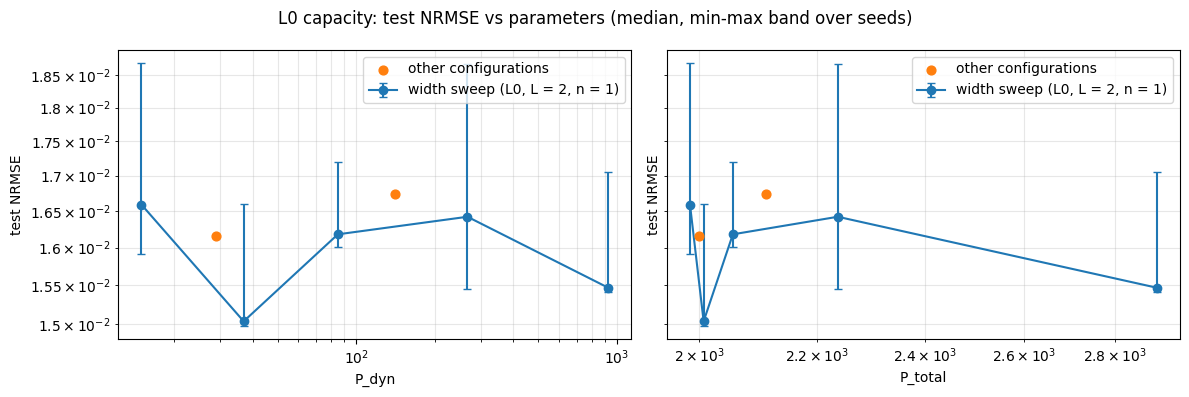

knee: width 2 (smallest width with the validation median within 10% of the best)
L0 power law: E_inf = 1.504e-02, a = 1.437e-03, alpha = 0.103 (95% CI [0.000, 0.565], 196 fits)
H1: FALSIFIED (exponent CI reaches below 0.1: flat in P_dyn)


In [13]:
show('L0')
plot_capacity('L0')
capacity_fit('L0')

## Stage 2. Latent dimension

Extra latent sizes at the canonical dynamics size: $n \in \{2,5,10\}$ (the paper's $\{1,5,10\}$ plus $2n^*$). $P_{\mathrm{dyn}}$, $P_{\mathrm{rec}}$ and $P_{\mathrm{total}}$ are reported separately because $n$ changes both networks (the reconstructor input layer grows with $n$).

In [ ]:
sweep(STAGE2, 'Stage 2 (latent size)')

In [ ]:
show('L0')
plot_capacity('L0')
h4_check('L0')
rank_table('L0')

## Stage 3. Iteration budget (no extra runs)

BFGS has no learning-rate schedule, so the checkpoints of the single long runs give the surface $\mathrm{error}(P, \mathrm{iterations})$ directly (protocol Sec. 5). This section only reads `curves.csv`.

In [ ]:
plot_iter_curves('L0')
time_to_target()
plot_cost_tradeoff(('L0',))

## Stage 5. Thread scaling and serial timing (Pass T)

Run this section alone, serially, plugged in, with nothing else running. TensorFlow only accepts its thread counts before it runs its first operation, so every timing is done in a **fresh process** (`timing_worker.py` re-executes the tagged setup cells of this notebook with the thread count fixed first). The unit measured is **seconds per joint function/gradient evaluation** on a stored run (median of 3 repeats of 20 evaluations, after a warm-up): it needs no new BFGS run and does not depend on how many line-search steps an iteration takes. `thread_scaling` times the canonical L0 run with 1, 2, 4, 6, 12 and 18 threads; `spot_timing` then times every stored configuration (L0 and L2, seed 0) at the chosen thread count and stores `timing.csv`. From then on `medians()` estimates the training time of a configuration as `n_fev` $\times$ `s_per_eval` (Pass T). Pass-A times from the sweeps stay orientation only.

In [ ]:
NB_NAME = 'TestCase_B_bis.ipynb'

def run_worker(threads, cfgs):
    '''Times configurations in a FRESH process: TensorFlow only accepts its thread counts before it runs its first operation,
    so one process per thread count (timing_worker.py re-executes this notebook's tagged setup cells).'''
    out = subprocess.run([sys.executable, 'timing_worker.py', str(threads), NB_NAME, json.dumps(cfgs)], capture_output = True, text = True)
    lines = [l for l in out.stdout.splitlines() if l.startswith('RESULT ')]
    assert lines, out.stderr[-3000:]
    return json.loads(lines[-1][len('RESULT '):])

def hardware_record(threads):
    sysctl = lambda k: subprocess.run(['sysctl', '-n', k], capture_output = True, text = True).stdout.strip()
    rec = dict(chip = sysctl('machdep.cpu.brand_string'), perf_cores = sysctl('hw.perflevel0.logicalcpu'), eff_cores = sysctl('hw.perflevel1.logicalcpu'),
               os = platform.platform(), python = sys.version.split()[0], tensorflow = tf.__version__, numpy = np.__version__,
               threads = threads)
    (OUT / 'hardware.json').write_text(json.dumps(rec, indent = 2))
    return rec

def thread_scaling():
    '''Seconds per function/gradient evaluation vs thread count on the canonical stored run (one fresh process per count); speedup and efficiency.'''
    cfg = [*CANON, SEEDS[0]]
    assert (OUT / 'weights' / f'{run_id(*cfg)}.npy').exists(), 'run Stage 0 first'
    rows = np.array([(t, run_worker(t, [cfg])[0]) for t in [1, 2, 4, 6, 12, 18]])
    for t, s in rows:
        print(f'threads {int(t):3d}: {s:.4f} s/evaluation')
    fig, axs = plt.subplots(1, 2, figsize = (12, 4))
    axs[0].plot(rows[:, 0], rows[0, 1] / rows[:, 1], 'o-')
    axs[0].plot(rows[:, 0], rows[:, 0], '--', label = 'ideal')
    axs[0].set(xlabel = 'threads', ylabel = 'speedup')
    axs[0].legend()
    axs[1].plot(rows[:, 0], (rows[0, 1] / rows[:, 1]) / rows[:, 0], 'o-')
    axs[1].set(xlabel = 'threads', ylabel = 'parallel efficiency')
    for ax in axs:
        ax.grid(True, alpha = 0.3)
    fig.suptitle('Thread scaling (Pass T, canonical run)')
    fig.tight_layout()
    plt.show()
    best = int(rows[np.argmax(rows[0, 1] / rows[:, 1] / np.sqrt(rows[:, 0])), 0])   # best speedup per sqrt(thread) trade-off
    print(f'suggested thread count: {best}')
    return best

def spot_timing(threads):
    '''Pass T: seconds per function/gradient evaluation of every stored configuration (seed 0), one process, random order, thread count fixed.
    Training time of a run is then n_fev x s_per_eval. The first configuration is timed again at the end (throttling check).'''
    hardware_record(threads)
    runs = load('runs')
    cfgs = [[*c, SEEDS[0]] for c in runs[runs.seed == SEEDS[0]][CFG_KEYS].drop_duplicates().itertuples(index = False, name = None)]
    cfgs = [c for c in cfgs if (OUT / 'weights' / f'{run_id(*c)}.npy').exists()]
    cfgs = [cfgs[i] for i in np.random.RandomState(0).permutation(len(cfgs))]     # randomized order (protocol Sec. 7)
    times = run_worker(threads, cfgs)
    pd.DataFrame([dict(zip(CFG_KEYS, c[:-1]), threads = threads, s_per_eval = s) for c, s in zip(cfgs, times)]).to_csv(OUT / 'timing.csv', index = False)
    again = run_worker(threads, [cfgs[0]])[0]
    print(f'timed {len(cfgs)} configurations; throttling check: first configuration {again:.4f} vs {times[0]:.4f} s/evaluation '
          f'({abs(again / times[0] - 1):.1%} apart; repeat the session if more than 10%)')

# Run in order, serially, plugged in, nothing else on the machine:
# best = thread_scaling()
# spot_timing(best)

## Stage 7. Linear reconstructor arm (L2, R2)

The same networks and training as L0, with the reconstructor replaced by the linear L2 of RQ2: $\bar y+\sum_{k=1}^{K}(W\mathbf{z}+\mathbf{b})_k\varphi_k$, where $\mathbf{z}$ is the latent state (case B: with the lid velocity $u$ appended). Only $W,\mathbf{b}$ ($K(\dim\mathbf{z}+1)$ parameters) and $\mathcal{NN}_{\mathrm{dyn}}$ are trained, end-to-end, with $K=65$ modes unless the $K$ sweep says otherwise. Three sweeps, 3 seeds each: **latent size $n$** at canonical dynamics (an affine map of $n$ latents spans at most an $n$-dimensional set of fields, so $n$ is what limits L2), **dynamics width** at the chosen $n=$ `N_L2`, and **number of modes $K$** at that $n$. The question is not only whether L2 is accurate but what an accuracy level **costs** compared with L0: operations, function evaluations and time to reach the same error (`cost_to_reach`).

In [ ]:
sweep(STAGE7, 'Stage 7 (L2 arm)')

In [ ]:
show('L2')
plot_linear_sweeps()
plot_arms()
cost_to_reach()
h4_check('L2')
capacity_fit('L2')
h2_split('L2')
plot_iter_curves('L2')
rank_table('L2')

## Final comparison

Headline trade-offs and the H1-H5 verdicts at the 1000-iteration BFGS-only budget, for both arms. All conclusions are conditional on this budget (protocol Sec. 10), never asymptotic.

In [ ]:
for v in ('L0', 'L2'):
    plot_capacity(v)
    capacity_fit(v)
    pareto_front(v)
    h2_split(v)
plot_arms()
cost_to_reach()
if (OUT / 'timing.csv').exists():
    plot_flops_check()
failure_map()
plot_svd_decay()